# Modelo supervisado para la actividad sísmica

En esta etapa se construyen y evalúan modelos supervisados para estimar la cantidad mensual de sismos en Argentina. Se utilizan los datos preparados en las etapas anteriores y distintos conjuntos de predictores derivados de la actividad sísmica, sus características y las variables de calidad del registro.

El análisis compara modelos estadísticos de referencia con modelos de Machine Learning, respetando el orden temporal de los datos y reservando un período final para la evaluación definitiva.


## Metodología y planificación del análisis

El objetivo es comparar distintas alternativas para estimar la cantidad de sismos del mes siguiente y, posteriormente, obtener estimaciones acumuladas para horizontes de 1, 3, 6 y 12 meses.

### Escenarios y conjuntos de predictores

Se trabajará con dos escenarios: uno que conserva el pico registrado en agosto de 2021 y otro que reemplaza ese valor por la mediana mensual. De esta manera se puede observar la influencia de ese valor extremo en el desempeño de los modelos.

Se evaluarán cuatro conjuntos de predictores:

1. **Predictores básicos:** cantidad de sismos del mes anterior.
2. **Actividad reciente:** cantidad de sismos de los últimos 1, 3 y 6 meses.
3. **Características sísmicas:** actividad reciente, junto con magnitud y profundidad resumidas de los meses anteriores.
4. **Catálogo completo:** los predictores anteriores más las variables de calidad y los errores de medición que puedan calcularse correctamente.

### Modelos y referencias

Las referencias estadísticas serán la persistencia —usar la cantidad de sismos del mes anterior— y la media móvil —usar el promedio de los últimos meses—. También se probarán una regresión lineal, Random Forest y XGBoost, con sus configuraciones correspondientes.

### Preprocesamiento y evaluación

Los predictores de los modelos de Machine Learning se normalizarán dentro de un `Pipeline` cuando corresponda. La variable objetivo se mantendrá en su escala original: cantidad de sismos.

La evaluación respetará el orden cronológico mediante una separación temporal y validación cruzada con `TimeSeriesSplit`. La búsqueda de hiperparámetros y la selección de predictores se realizarán únicamente con los datos de desarrollo. El conjunto de prueba final permanecerá separado hasta la evaluación definitiva.

Los modelos se compararán utilizando MAE, RMSE y estabilidad temporal, además de gráficos de valores reales frente a predichos y de los errores. Todos se evaluarán sobre los mismos períodos y con las mismas métricas.

### Selección final y horizontes de predicción

Se seleccionará la alternativa más adecuada considerando rendimiento, estabilidad y complejidad. Luego se evaluará una sola vez sobre el período de prueba final y se comparará con las referencias estadísticas. Para los horizontes de varios meses se considerará una predicción mensual recursiva, sin utilizar los valores reales de meses futuros durante la estimación.


# 1. Importación de librerías


In [3]:
# Sistema y manipulación de datos
import os
import numpy as np
import pandas as pd
import geopandas as gpd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Preparación de modelos
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Modelos de regresión
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.dummy import DummyRegressor

# Validación cruzada y evaluación
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Combinaciones de hiperparámetros
from itertools import product

# 2. Carga y revisión de datos


In [4]:
datos = pd.read_csv("../data/processed/sismos_argentina_limpio.csv")

datos.head(3)


,time,latitude,longitude,depth,mag,magType,gap,dmin,rms,id,updated,place,horizontalError,depthError,magError,magNst,event_year,event_month,event_day,event_hour
0,2026-09-14 05:03:12.877000+00:00,-24.1313,-66.9986,189.041,4.4,mb,77.0,2.572,0.66,us7000than,2026-09-14 06:21:54.040000+00:00,"69 km W of San Antonio de los Cobres, Argentina",3.33,13.010,0.149,13.0,2026,9,14,5
1,2026-09-13 19:40:25.496000+00:00,-26.1509,-66.6119,10.000,4.7,mb,54.0,2.863,0.78,us7000th7y,2026-09-24 17:19:43.040000+00:00,"64 km W of Cafayate, Argentina",6.25,1.889,0.088,39.0,2026,9,13,19
2,2026-09-12 11:05:46.433000+00:00,-56.2951,-26.9013,102.352,4.9,mb,67.0,5.836,0.79,us7000tgyw,2026-09-23 07:20:17.040000+00:00,South Sandwich Islands region,12.33,7.797,0.106,28.0,2026,9,12,11


In [5]:
datos.info()

<class 'pandas.DataFrame'>
RangeIndex: 6427 entries, 0 to 6426
Data columns (total 20 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   time             6427 non-null   str    
 1   latitude         6427 non-null   float64
 2   longitude        6427 non-null   float64
 3   depth            6427 non-null   float64
 4   mag              6427 non-null   float64
 5   magType          6427 non-null   str    
 6   gap              6427 non-null   float64
 7   dmin             6427 non-null   float64
 8   rms              6427 non-null   float64
 9   id               6427 non-null   str    
 10  updated          6427 non-null   str    
 11  place            6427 non-null   str    
 12  horizontalError  6427 non-null   float64
 13  depthError       6427 non-null   float64
 14  magError         6427 non-null   float64
 15  magNst           6427 non-null   float64
 16  event_year       6427 non-null   int64  
 17  event_month      6427 non

# 3. Preparación temporal y exclusión de meses extremos


In [6]:

# Convertir la columna de fechas a formato datetime
datos["time"] = pd.to_datetime(datos["time"], format="mixed", utc=True)


# Verificar las fechas extremas de cada mes
meses_extremos = ["2016-09", "2026-09"]

for mes in meses_extremos:
    registros = datos.loc[
        datos["time"].dt.strftime("%Y-%m") == mes, "time"
    ]

    print(f"{mes}:")
    print(f"  Primer registro: {registros.min()}")
    print(f"  Último registro: {registros.max()}")
    print()


# Excluir los dos meses extremos identificados en la auditoría
meses = datos["time"].dt.strftime("%Y-%m")

datos = datos.loc[
    ~meses.isin(meses_extremos)
].copy()


# Verificar el período y la cantidad de registros conservados
print("Período conservado:",
      datos["time"].min(), "a", datos["time"].max())
print("Registros conservados:", len(datos))


2016-09:
  Primer registro: 2016-09-15 01:06:30.870000+00:00
  Último registro: 2016-09-30 13:12:56.160000+00:00

2026-09:
  Primer registro: 2026-09-02 10:54:04.332000+00:00
  Último registro: 2026-09-14 05:03:12.877000+00:00

Período conservado: 2016-10-01 08:05:13.730000+00:00 a 2026-08-31 21:45:56.991000+00:00
Registros conservados: 6372


# 4. Conteo de sismos por mes


In [7]:

conteos = (
    datos
    .groupby(["event_year", "event_month"])
    .size()
    .rename("cantidad_sismos")
    .reset_index()
    .sort_values(["event_year", "event_month"])
    .reset_index(drop=True)
)

display(conteos)

print("\nValores faltantes:")
display(conteos.isna().sum())


,event_year,event_month,cantidad_sismos
0,2016,10,48
1,2016,11,51
2,2016,12,33
3,2017,1,46
4,2017,2,36
...,...,...,...
114,2026,4,31
115,2026,5,51
116,2026,6,39
117,2026,7,51



Valores faltantes:


event_year         0
event_month        0
cantidad_sismos    0
dtype: int64

### Escenario alternativo por valor extremo

Dado el pico excepcional en la cantidad de sismos registrado en agosto de 2021, se trabajará en paralelo con dos versiones del dataset: una que conserva los datos originales y otra en la que el valor de ese mes se reemplaza por la mediana de la cantidad mensual de sismos. Esto permitirá analizar la influencia del valor extremo en el desempeño de los modelos predictivos y comparar sus resultados frente a una misma línea base estadística.

## 4.1. Preparación del escenario alternativo


In [8]:

print(conteos[conteos["event_year"]==2021])

conteos_agost = conteos.copy()

mascara_agosto = (
    (conteos_agost["event_year"] == 2021) &
    (conteos_agost["event_month"] == 8)
)

print("Antes:", conteos_agost.loc[mascara_agosto, "cantidad_sismos"].iloc[0])

conteos_agost.loc[mascara_agosto, "cantidad_sismos"] = conteos_agost["cantidad_sismos"].median()

print("Después:", conteos_agost.loc[mascara_agosto, "cantidad_sismos"].iloc[0])


    event_year  event_month  cantidad_sismos
51        2021            1              103
52        2021            2               40
53        2021            3               39
54        2021            4               49
55        2021            5               44
56        2021            6               46
57        2021            7               36
58        2021            8              600
59        2021            9              156
60        2021           10               86
61        2021           11               82
62        2021           12              101
Antes: 600
Después: 46


### Definición de los conjuntos de predictores

1. Predictores básicos:	Cantidad de sismos del mes anterior.
2. Actividad reciente:	Cantidad de sismos de los últimos 1, 3 y 6 meses.
3. Características sísmicas:	Actividad reciente + magnitud y profundidad resumidas de los meses anteriores.
4. Catálogo completo:	Los anteriores + variables de calidad y errores de medición que puedan calcularse correctamente.

# 5. Creación de predictores


In [9]:

# ------------------------------------------------------------
# CARACTERÍSTICAS SÍSMICAS MENSUALES

caracteristicas_sismicas = (
    datos
    .groupby(["event_year", "event_month"])
    .agg(
        magnitud_media=("mag", "mean"),
        magnitud_maxima=("mag", "max"),
        profundidad_media=("depth", "mean"),
        profundidad_maxima=("depth", "max")
    )
    .reset_index()
)

# ------------------------------------------------------------
# VARIABLES DE CALIDAD MENSUALES

columnas_calidad = [
    "gap",
    "dmin",
    "rms",
    "horizontalError",
    "depthError",
    "magError",
    "magNst"
]

calidad_mensual = (
    datos
    .groupby(["event_year", "event_month"])[columnas_calidad]
    .mean()
    .reset_index()
)

print("Características sísmicas:")
display(caracteristicas_sismicas.head())

print("Variables de calidad:")
display(calidad_mensual.head())


Características sísmicas:


,event_year,event_month,magnitud_media,magnitud_maxima,profundidad_media,profundidad_maxima
0,2016,10,4.431250,5.3,110.537083,605.91
1,2016,11,4.511765,6.4,135.380392,572.55
2,2016,12,4.418182,5.4,103.462727,249.59
3,2017,1,4.573913,5.4,76.727826,232.83
4,2017,2,4.619444,6.4,98.277500,530.80


Variables de calidad:


,event_year,event_month,gap,dmin,rms,horizontalError,depthError,magError,magNst
0,2016,10,88.104167,3.933250,0.864375,9.100000,5.495833,0.157771,28.250000
1,2016,11,94.000000,3.367039,0.784314,9.092157,6.188235,0.162529,29.823529
2,2016,12,89.878788,3.674970,0.892424,9.421212,7.930303,0.179485,22.757576
3,2017,1,94.434783,7.525609,0.830652,9.686957,5.804348,0.148109,26.804348
4,2017,2,76.388889,4.980778,0.865833,7.977778,7.300000,0.140417,27.833333


## 5.1. Función para crear los cuatro predictores


In [10]:

# ------------------------------------------------------------
# FUNCIÓN PARA CREAR LOS CUATRO PREDICTORES

def crear_predictores(conteos_mensuales):

    # P1: cantidad de sismos del mes anterior
    P1 = conteos_mensuales.copy()

    P1["sismos_mes_anterior"] = (
        P1["cantidad_sismos"].shift(1)
    )

    # P2: agregar actividad acumulada de los meses anteriores
    P2 = P1.copy()

    P2["sismos_ultimos_3_meses"] = (
        P2["cantidad_sismos"].shift(1).rolling(3).sum()
    )

    P2["sismos_ultimos_6_meses"] = (
        P2["cantidad_sismos"].shift(1).rolling(6).sum()
    )

    # P3: agregar características sísmicas de los meses anteriores
    P3 = P2.merge(
        caracteristicas_sismicas,
        on=["event_year", "event_month"],
        how="left"
    )

    columnas_sismicas = [
        "magnitud_media",
        "magnitud_maxima",
        "profundidad_media",
        "profundidad_maxima"
    ]

    for columna in columnas_sismicas:
        P3[columna] = P3[columna].shift(1)

    # P4: agregar variables de calidad de los meses anteriores
    P4 = P3.merge(
        calidad_mensual,
        on=["event_year", "event_month"],
        how="left"
    )

    for columna in columnas_calidad:
        P4[columna] = P4[columna].shift(1)


    # ------------------------------------------------------------
    # IGUALAR EL PERÍODO DE LOS CUATRO PREDICTORES
    #
    # P2 necesita seis meses previos para calcular la suma móvil
    # de seis meses. Además, P1, P3 y P4 incorporan variables
    # desplazadas que requieren información de meses anteriores.
    #
    # Descartamos las primeras seis filas de las cuatro tablas
    # para comparar todos los predictores sobre el mismo período.
    # ------------------------------------------------------------

    predictores = {
        "Predictor 1": P1,
        "Predictor 2": P2,
        "Predictor 3": P3,
        "Predictor 4": P4
    }

    predictores_limpios = {}

    for nombre, tabla in predictores.items():
        predictores_limpios[nombre] = (
            tabla.iloc[6:].copy().reset_index(drop=True)
        )

    return predictores_limpios

# es un diccionario de 4 tablas
# cada tabla con un nombre




## 5.2. Preparación de los escenarios


In [11]:

# ------------------------------------------------------------
# ESCENARIO ORIGINAL Y ESCENARIO CON MEDIANA

predictores_limpios = crear_predictores(conteos)

predictores_limpiosA = crear_predictores(conteos_agost)


# Revisar las tablas resultantes
for nombre, tabla in predictores_limpios.items():
    print(f"\n{nombre}")
    print(f"Filas: {len(tabla)}")
    print(f"Valores faltantes: {tabla.isna().sum().sum()}")

print("\nEscenario con agosto reemplazado por la mediana:")

for nombre, tabla in predictores_limpiosA.items():
    print(f"\n{nombre}")
    print(f"Filas: {len(tabla)}")
    print(f"Valores faltantes: {tabla.isna().sum().sum()}")



Predictor 1
Filas: 113
Valores faltantes: 0

Predictor 2
Filas: 113
Valores faltantes: 0

Predictor 3
Filas: 113
Valores faltantes: 0

Predictor 4
Filas: 113
Valores faltantes: 0

Escenario con agosto reemplazado por la mediana:

Predictor 1
Filas: 113
Valores faltantes: 0

Predictor 2
Filas: 113
Valores faltantes: 0

Predictor 3
Filas: 113
Valores faltantes: 0

Predictor 4
Filas: 113
Valores faltantes: 0


# 6. Preparación de los datos para entrenamiento y prueba


In [12]:

# Reservar los últimos 12 meses para evaluar los modelos
cantidad_meses_prueba = 12

columnas_excluir = [
    "event_year",
    "event_month",
    "cantidad_sismos"
]


def preparar_datos_modelos(predictores_limpios):

    datos_modelos = {}

    for nombre, tabla in predictores_limpios.items():

        # Separar los últimos 12 meses para la prueba
        entrenamiento = tabla.iloc[:-cantidad_meses_prueba].copy()
        prueba = tabla.iloc[-cantidad_meses_prueba:].copy()

        # Definir predictores (X) y variable objetivo (y)
        X_train = entrenamiento.drop(columns=columnas_excluir)
        y_train = entrenamiento["cantidad_sismos"]

        X_test = prueba.drop(columns=columnas_excluir)
        y_test = prueba["cantidad_sismos"]

        # Guardar los conjuntos para utilizarlos después
        datos_modelos[nombre] = {
            "X_train": X_train,
            "y_train": y_train,
            "X_test": X_test,
            "y_test": y_test,
            "prueba": prueba
        }

    return datos_modelos


# Preparar ambos escenarios
datos_modelos = preparar_datos_modelos(predictores_limpios)
datos_modelosA = preparar_datos_modelos(predictores_limpiosA)


In [13]:
for nombre, datos in datos_modelos.items():
    print(f"\n{nombre}")
    print("Predictores:", list(datos["X_train"].columns))
    print("Variable objetivo:", datos["y_train"].name)


Predictor 1
Predictores: ['sismos_mes_anterior']
Variable objetivo: cantidad_sismos

Predictor 2
Predictores: ['sismos_mes_anterior', 'sismos_ultimos_3_meses', 'sismos_ultimos_6_meses']
Variable objetivo: cantidad_sismos

Predictor 3
Predictores: ['sismos_mes_anterior', 'sismos_ultimos_3_meses', 'sismos_ultimos_6_meses', 'magnitud_media', 'magnitud_maxima', 'profundidad_media', 'profundidad_maxima']
Variable objetivo: cantidad_sismos

Predictor 4
Predictores: ['sismos_mes_anterior', 'sismos_ultimos_3_meses', 'sismos_ultimos_6_meses', 'magnitud_media', 'magnitud_maxima', 'profundidad_media', 'profundidad_maxima', 'gap', 'dmin', 'rms', 'horizontalError', 'depthError', 'magError', 'magNst']
Variable objetivo: cantidad_sismos


# 7. Modelo de referencia: DummyRegressor


In [14]:

from sklearn.dummy import DummyRegressor

# Validación cruzada temporal: 5 pliegues de 12 meses
cv_temporal = TimeSeriesSplit(n_splits=5, test_size=12)


def evaluar_dummy(datos_modelos, escenario):

    resultados_cv = []
    resultados_test = []
    predicciones_dummy = {}

    for nombre, datos in datos_modelos.items():

        X_train = datos["X_train"]
        y_train = datos["y_train"]
        X_test = datos["X_test"]
        y_test = datos["y_test"]

        # ------------------------------------------------------
        # VALIDACIÓN CRUZADA TEMPORAL

        errores_mae = []
        errores_rmse = []

        for idx_train, idx_val in cv_temporal.split(X_train):

            modelo = DummyRegressor(strategy="mean")

            modelo.fit(
                X_train.iloc[idx_train],
                y_train.iloc[idx_train]
            )

            pred = modelo.predict(X_train.iloc[idx_val])
            real = y_train.iloc[idx_val]

            errores_mae.append(mean_absolute_error(real, pred))
            errores_rmse.append(
                np.sqrt(mean_squared_error(real, pred))
            )

        resultados_cv.append({
            "Escenario": escenario,
            "Predictor": nombre,
            "MAE_CV": np.mean(errores_mae),
            "MAE_CV_std": np.std(errores_mae),
            "RMSE_CV": np.mean(errores_rmse),
            "RMSE_CV_std": np.std(errores_rmse)
        })

        # ------------------------------------------------------
        # PRUEBA FINAL

        modelo_final = DummyRegressor(strategy="mean")
        modelo_final.fit(X_train, y_train)

        pred_test = modelo_final.predict(X_test)

        resultados_test.append({
            "Escenario": escenario,
            "Predictor": nombre,
            "MAE_test": mean_absolute_error(y_test, pred_test),
            "RMSE_test": np.sqrt(
                mean_squared_error(y_test, pred_test)
            )
        })

        predicciones_dummy[(escenario, nombre)] = pd.DataFrame({
            "Real": y_test.to_numpy(),
            "Predicción": pred_test
        })

    return (
        pd.DataFrame(resultados_cv),
        pd.DataFrame(resultados_test),
        predicciones_dummy
    )


## 7.1. Evaluación de los escenarios


In [15]:

# ------------------------------------------------------------
# EVALUAR ESCENARIO ORIGINAL Y ESCENARIO CON MEDIANA

cv_base_original, test_base_original, predicciones_base_original = (
    evaluar_dummy(datos_modelos, "Agosto original")
)

cv_base_mediana, test_base_mediana, predicciones_base_mediana = (
    evaluar_dummy(datos_modelosA, "Agosto reemplazado por mediana")
)


# Unificar resultados de validación cruzada y prueba
cv_base = pd.concat(
    [cv_base_original, cv_base_mediana],
    ignore_index=True
)

test_base = pd.concat(
    [test_base_original, test_base_mediana],
    ignore_index=True
)

predicciones_base = {
    **predicciones_base_original,
    **predicciones_base_mediana
}


# Revisar resultados
print("Resultados de validación cruzada:")
display(cv_base)

print("Resultados de prueba final:")
display(test_base)


Resultados de validación cruzada:


,Escenario,Predictor,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
0,Agosto original,Predictor 1,25.351825,20.196847,49.198388,58.093308
1,Agosto original,Predictor 2,25.351825,20.196847,49.198388,58.093308
2,Agosto original,Predictor 3,25.351825,20.196847,49.198388,58.093308
3,Agosto original,Predictor 4,25.351825,20.196847,49.198388,58.093308
4,Agosto reemplazado por mediana,Predictor 1,16.677538,10.789155,21.319184,13.888622
5,Agosto reemplazado por mediana,Predictor 2,16.677538,10.789155,21.319184,13.888622
6,Agosto reemplazado por mediana,Predictor 3,16.677538,10.789155,21.319184,13.888622
7,Agosto reemplazado por mediana,Predictor 4,16.677538,10.789155,21.319184,13.888622


Resultados de prueba final:


,Escenario,Predictor,MAE_test,RMSE_test
0,Agosto original,Predictor 1,11.349010,13.424465
1,Agosto original,Predictor 2,11.349010,13.424465
2,Agosto original,Predictor 3,11.349010,13.424465
3,Agosto original,Predictor 4,11.349010,13.424465
4,Agosto reemplazado por mediana,Predictor 1,8.355611,10.544251
5,Agosto reemplazado por mediana,Predictor 2,8.355611,10.544251
6,Agosto reemplazado por mediana,Predictor 3,8.355611,10.544251
7,Agosto reemplazado por mediana,Predictor 4,8.355611,10.544251


# 8. Modelo: regresión lineal


In [16]:

# ------------------------------------------------------------
# VALIDACIÓN CRUZADA TEMPORAL

cv_temporal = TimeSeriesSplit(
    n_splits=5,
    test_size=12
)


def evaluar_regresion_lineal(datos_modelos, escenario):

    modelos_rl = {}
    predicciones_rl = {}
    resultados_cv = []
    resultados_test = []

    for nombre, datos in datos_modelos.items():

        X_train = datos["X_train"]
        y_train = datos["y_train"]
        X_test = datos["X_test"]
        y_test = datos["y_test"]

        # ----------------------------------------------------
        # CREAR MODELO

        modelo = Pipeline([
            ("escalador", StandardScaler()),
            ("regresion", LinearRegression())
        ])

        # ----------------------------------------------------
        # VALIDACIÓN CRUZADA TEMPORAL

        errores_mae = []
        errores_rmse = []

        for idx_train, idx_val in cv_temporal.split(X_train):

            X_train_cv = X_train.iloc[idx_train]
            y_train_cv = y_train.iloc[idx_train]

            X_val_cv = X_train.iloc[idx_val]
            y_val_cv = y_train.iloc[idx_val]

            modelo_cv = Pipeline([
                ("escalador", StandardScaler()),
                ("regresion", LinearRegression())
            ])

            modelo_cv.fit(X_train_cv, y_train_cv)

            pred_cv = modelo_cv.predict(X_val_cv)

            errores_mae.append(
                mean_absolute_error(y_val_cv, pred_cv)
            )

            errores_rmse.append(
                np.sqrt(mean_squared_error(y_val_cv, pred_cv))
            )

        resultados_cv.append({
            "Escenario": escenario,
            "Predictor": nombre,
            "MAE_CV": np.mean(errores_mae),
            "MAE_CV_std": np.std(errores_mae, ddof=1),
            "RMSE_CV": np.mean(errores_rmse),
            "RMSE_CV_std": np.std(errores_rmse, ddof=1)
        })

        # ----------------------------------------------------
        # ENTRENAMIENTO FINAL Y PRUEBA

        modelo.fit(X_train, y_train)

        pred_test = modelo.predict(X_test)

        modelos_rl[nombre] = modelo

        predicciones_rl[nombre] = pd.DataFrame({
            "Real": y_test.to_numpy(),
            "Predicción": pred_test
        }, index=y_test.index)

        resultados_test.append({
            "Escenario": escenario,
            "Predictor": nombre,
            "MAE_test": mean_absolute_error(y_test, pred_test),
            "RMSE_test": np.sqrt(
                mean_squared_error(y_test, pred_test)
            )
        })

    return (
        modelos_rl,
        predicciones_rl,
        pd.DataFrame(resultados_cv),
        pd.DataFrame(resultados_test)
    )


In [17]:

# ------------------------------------------------------------
# ESCENARIO ORIGINAL: AGOSTO DE 2021 SIN MODIFICAR

(
    modelos_regresion_lineal,
    predicciones_regresion_lineal,
    tabla_cv_lineal,
    tabla_test_lineal
) = evaluar_regresion_lineal(
    datos_modelos,
    "Agosto original"
)


# ------------------------------------------------------------
# ESCENARIO ALTERNATIVO: AGOSTO DE 2021 REEMPLAZADO POR LA MEDIANA

(
    modelos_regresion_linealA,
    predicciones_regresion_linealA,
    tabla_cv_linealA,
    tabla_test_linealA
) = evaluar_regresion_lineal(
    datos_modelosA,
    "Agosto reemplazado por mediana"
)


# ------------------------------------------------------------
# UNIFICAR RESULTADOS

resultados_cv_lineal = pd.concat(
    [tabla_cv_lineal, tabla_cv_linealA],
    ignore_index=True
)

resultados_test_lineal = pd.concat(
    [tabla_test_lineal, tabla_test_linealA],
    ignore_index=True
)


# ------------------------------------------------------------
# MOSTRAR RESULTADOS

print("RESULTADOS DE VALIDACIÓN CRUZADA TEMPORAL")
display(resultados_cv_lineal.round(3))

print("\nRESULTADOS EN LOS 12 MESES DE PRUEBA")
display(resultados_test_lineal.round(3))


RESULTADOS DE VALIDACIÓN CRUZADA TEMPORAL


,Escenario,Predictor,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
0,Agosto original,Predictor 1,24.647,22.630,48.583,65.308
1,Agosto original,Predictor 2,29.656,26.253,57.565,66.980
2,Agosto original,Predictor 3,30.563,24.723,59.462,66.350
3,Agosto original,Predictor 4,80.370,83.401,122.052,122.543
4,Agosto reemplazado por mediana,Predictor 1,14.579,6.916,19.856,12.240
5,Agosto reemplazado por mediana,Predictor 2,13.412,5.734,18.975,11.186
6,Agosto reemplazado por mediana,Predictor 3,14.244,5.215,21.087,12.374
7,Agosto reemplazado por mediana,Predictor 4,18.657,8.770,25.045,15.056



RESULTADOS EN LOS 12 MESES DE PRUEBA


,Escenario,Predictor,MAE_test,RMSE_test
0,Agosto original,Predictor 1,10.121,12.165
1,Agosto original,Predictor 2,9.796,11.689
2,Agosto original,Predictor 3,10.441,11.962
3,Agosto original,Predictor 4,13.875,20.134
4,Agosto reemplazado por mediana,Predictor 1,8.893,9.938
5,Agosto reemplazado por mediana,Predictor 2,8.589,10.094
6,Agosto reemplazado por mediana,Predictor 3,12.717,13.689
7,Agosto reemplazado por mediana,Predictor 4,11.878,12.536


# 9. Modelo: Random Forest


In [20]:

# ------------------------------------------------------------
# GRILLA DE HIPERPARÁMETROS

grilla_rf = list(product(
    [100, 200],  # Cantidad de árboles
    [3, None],   # Profundidad máxima
    [2, 4]       # Mínimo de observaciones por hoja
))


def evaluar_random_forest(datos_modelos, escenario):

    resultados_cv = []
    resultados_test = []
    modelos_rf = {}
    predicciones_rf = {}
    hiperparametros_rf = {}
    resultados_busqueda_rf = {}

    for nombre, datos in datos_modelos.items():

        X_train = datos["X_train"].reset_index(drop=True)
        y_train = datos["y_train"].reset_index(drop=True)
        X_test = datos["X_test"].reset_index(drop=True)
        y_test = datos["y_test"].reset_index(drop=True)

        # ----------------------------------------------------
        # BÚSQUEDA DE HIPERPARÁMETROS CON CV TEMPORAL

        resultados_combinaciones = []

        for n_arboles, profundidad, hoja in grilla_rf:

            errores_mae = []
            errores_rmse = []

            for idx_train, idx_val in cv_temporal.split(X_train):

                modelo_cv = RandomForestRegressor(
                    n_estimators=n_arboles,
                    max_depth=profundidad,
                    min_samples_leaf=hoja,
                    random_state=42,
                    n_jobs=-1
                )

                modelo_cv.fit(
                    X_train.iloc[idx_train],
                    y_train.iloc[idx_train]
                )

                pred_cv = modelo_cv.predict(
                    X_train.iloc[idx_val]
                )

                real_cv = y_train.iloc[idx_val]

                errores_mae.append(
                    mean_absolute_error(real_cv, pred_cv)
                )

                errores_rmse.append(
                    np.sqrt(
                        mean_squared_error(real_cv, pred_cv)
                    )
                )

            resultados_combinaciones.append({
                "n_estimators": n_arboles,
                "max_depth": profundidad,
                "min_samples_leaf": hoja,
                "MAE_CV": np.mean(errores_mae),
                "MAE_CV_std": np.std(errores_mae, ddof=1),
                "RMSE_CV": np.mean(errores_rmse),
                "RMSE_CV_std": np.std(errores_rmse, ddof=1)
            })

        # Ordenar las combinaciones por MAE y luego por RMSE
        tabla_busqueda = pd.DataFrame(resultados_combinaciones)

        tabla_busqueda = tabla_busqueda.sort_values(
            ["MAE_CV", "RMSE_CV"]
        ).reset_index(drop=True)

        resultados_busqueda_rf[(escenario, nombre)] = tabla_busqueda

        # Seleccionar la mejor combinación
        mejor = tabla_busqueda.iloc[0]

        parametros = {
            "n_estimators": int(mejor["n_estimators"]),
            "max_depth": (
                None if pd.isna(mejor["max_depth"])
                else int(mejor["max_depth"])
            ),
            "min_samples_leaf": int(mejor["min_samples_leaf"])
        }
        # ----------------------------------------------------
        # ENTRENAMIENTO FINAL CON TODO EL CONJUNTO DE
        # ENTRENAMIENTO

        modelo_final = RandomForestRegressor(
            **parametros,
            random_state=42,
            n_jobs=-1
        )

        modelo_final.fit(X_train, y_train)

        # ----------------------------------------------------
        # EVALUACIÓN EN LOS 12 MESES DE PRUEBA

        pred_test = modelo_final.predict(X_test)

        modelos_rf[(escenario, nombre)] = modelo_final

        predicciones_rf[(escenario, nombre)] = pd.DataFrame({
            "Real": y_test.to_numpy(),
            "Predicción": pred_test
        })

        hiperparametros_rf[(escenario, nombre)] = parametros

        # Guardar métricas de validación cruzada
        resultados_cv.append({
            "Escenario": escenario,
            "Predictor": nombre,
            "MAE_CV": mejor["MAE_CV"],
            "MAE_CV_std": mejor["MAE_CV_std"],
            "RMSE_CV": mejor["RMSE_CV"],
            "RMSE_CV_std": mejor["RMSE_CV_std"],
            "Hiperparámetros": str(parametros)
        })

        # Guardar métricas de prueba
        resultados_test.append({
            "Escenario": escenario,
            "Predictor": nombre,
            "MAE_test": mean_absolute_error(y_test, pred_test),
            "RMSE_test": np.sqrt(
                mean_squared_error(y_test, pred_test)
            )
        })

    return (
        pd.DataFrame(resultados_cv),
        pd.DataFrame(resultados_test),
        modelos_rf,
        predicciones_rf,
        hiperparametros_rf,
        resultados_busqueda_rf
    )


In [21]:

# ------------------------------------------------------------
# ESCENARIO ORIGINAL: AGOSTO SIN MODIFICAR

(
    cv_rf_original,
    test_rf_original,
    modelos_rf_original,
    predicciones_rf_original,
    hiperparametros_rf_original,
    busqueda_rf_original
) = evaluar_random_forest(
    datos_modelos,
    "Agosto original"
)


# ------------------------------------------------------------
# ESCENARIO ALTERNATIVO: AGOSTO REEMPLAZADO POR LA MEDIANA

(
    cv_rf_mediana,
    test_rf_mediana,
    modelos_rf_mediana,
    predicciones_rf_mediana,
    hiperparametros_rf_mediana,
    busqueda_rf_mediana
) = evaluar_random_forest(
    datos_modelosA,
    "Agosto reemplazado por mediana"
)


# ------------------------------------------------------------
# UNIFICAR RESULTADOS

comparacion_cv_rf = pd.concat(
    [cv_rf_original, cv_rf_mediana],
    ignore_index=True
)

comparacion_test_rf = pd.concat(
    [test_rf_original, test_rf_mediana],
    ignore_index=True
)


# ------------------------------------------------------------
# MOSTRAR RESULTADOS

print("RESULTADOS DE VALIDACIÓN CRUZADA")
display(
    comparacion_cv_rf
    .sort_values(["Escenario", "MAE_CV"])
    .round(3)
)

print("\nRESULTADOS EN LOS 12 MESES DE PRUEBA")
display(
    comparacion_test_rf
    .sort_values(["Escenario", "MAE_test"])
    .round(3)
)


RESULTADOS DE VALIDACIÓN CRUZADA


,Escenario,Predictor,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std,Hiperparámetros
0,Agosto original,Predictor 1,23.900,23.141,47.597,66.070,"{'n_estimators': 200, 'max_depth': None, 'min_..."
1,Agosto original,Predictor 2,25.856,21.894,50.618,62.951,"{'n_estimators': 200, 'max_depth': None, 'min_..."
2,Agosto original,Predictor 3,27.377,20.915,53.092,62.362,"{'n_estimators': 200, 'max_depth': 3, 'min_sam..."
3,Agosto original,Predictor 4,37.394,18.491,60.721,58.109,"{'n_estimators': 200, 'max_depth': 3, 'min_sam..."
6,Agosto reemplazado por mediana,Predictor 3,14.264,6.933,20.004,11.977,"{'n_estimators': 200, 'max_depth': 3, 'min_sam..."
5,Agosto reemplazado por mediana,Predictor 2,14.601,6.704,20.172,11.779,"{'n_estimators': 100, 'max_depth': 3, 'min_sam..."
7,Agosto reemplazado por mediana,Predictor 4,15.018,8.049,20.900,12.692,"{'n_estimators': 200, 'max_depth': 3, 'min_sam..."
4,Agosto reemplazado por mediana,Predictor 1,15.728,6.186,21.382,11.220,"{'n_estimators': 200, 'max_depth': 3, 'min_sam..."



RESULTADOS EN LOS 12 MESES DE PRUEBA


,Escenario,Predictor,MAE_test,RMSE_test
3,Agosto original,Predictor 4,8.697,10.759
2,Agosto original,Predictor 3,11.455,19.117
1,Agosto original,Predictor 2,16.076,21.929
0,Agosto original,Predictor 1,21.168,34.364
7,Agosto reemplazado por mediana,Predictor 4,8.501,10.042
5,Agosto reemplazado por mediana,Predictor 2,8.806,10.894
6,Agosto reemplazado por mediana,Predictor 3,8.834,10.693
4,Agosto reemplazado por mediana,Predictor 1,9.263,10.840


## 9.1. Comparación de las combinaciones probadas


In [23]:

# ------------------------------------------------------------
# COMPARAR LAS COMBINACIONES PROBADAS

for clave, tabla in busqueda_rf_original.items():

    print(f"\nEscenario: {clave[0]} | {clave[1]}")
    tabla_mostrar = tabla.copy()

    tabla_mostrar["max_depth"] = (
        tabla_mostrar["max_depth"].astype(object).where(
            tabla_mostrar["max_depth"].notna(),
            "Sin límite"
        )
    )

    display(tabla_mostrar.round(3))



Escenario: Agosto original | Predictor 1


,n_estimators,max_depth,min_samples_leaf,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
0,200,Sin límite,4,23.900,23.141,47.597,66.070
1,200,3.0,4,23.938,23.063,47.421,66.161
2,100,Sin límite,4,23.997,23.090,47.771,66.050
3,100,3.0,4,24.000,23.039,47.578,66.134
4,200,3.0,2,25.907,22.507,51.386,64.142
5,100,3.0,2,26.004,22.409,51.696,64.084
6,200,Sin límite,2,26.784,22.520,52.436,63.642
7,100,Sin límite,2,26.812,22.454,52.564,63.685



Escenario: Agosto original | Predictor 2


,n_estimators,max_depth,min_samples_leaf,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
0,200,Sin límite,4,25.856,21.894,50.618,62.951
1,200,3.0,4,25.910,21.812,50.647,62.940
2,200,3.0,2,26.032,21.840,53.195,61.912
3,100,Sin límite,4,26.209,21.803,51.487,62.650
4,100,3.0,4,26.252,21.723,51.536,62.628
5,100,3.0,2,26.510,21.586,54.568,61.330
6,200,Sin límite,2,27.145,21.669,54.193,61.566
7,100,Sin límite,2,27.460,21.681,55.319,61.187



Escenario: Agosto original | Predictor 3


,n_estimators,max_depth,min_samples_leaf,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
0,200,3.0,4,27.377,20.915,53.092,62.362
1,200,Sin límite,4,27.379,20.885,53.204,62.226
2,100,3.0,4,28.068,20.658,54.314,61.836
3,100,Sin límite,4,28.117,20.605,54.369,61.696
4,200,Sin límite,2,28.267,20.855,57.532,61.569
5,200,3.0,2,28.281,20.944,57.464,61.689
6,100,Sin límite,2,28.580,20.565,57.936,61.196
7,100,3.0,2,28.628,20.693,57.893,61.420



Escenario: Agosto original | Predictor 4


,n_estimators,max_depth,min_samples_leaf,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
0,200,3.0,4,37.394,18.491,60.721,58.109
1,200,Sin límite,4,37.484,18.424,60.892,57.966
2,100,3.0,4,39.436,19.051,62.887,57.324
3,100,Sin límite,4,39.605,18.866,63.071,57.152
4,200,3.0,2,57.449,48.642,82.622,64.950
5,200,Sin límite,2,57.626,48.484,82.786,64.777
6,100,3.0,2,61.008,49.743,87.143,63.513
7,100,Sin límite,2,61.179,49.667,87.299,63.407


# 10. Modelo: XGBoost


In [24]:

# ------------------------------------------------------------
# GRILLA DE HIPERPARÁMETROS

grilla_xgb = list(product(
    [100, 200],  # Cantidad de árboles
    [2, 3],      # Profundidad máxima
    [0.03, 0.1]  # Tasa de aprendizaje
))

print("Combinaciones por predictor y escenario:", len(grilla_xgb))


# ------------------------------------------------------------
# FUNCIÓN DE EVALUACIÓN

def evaluar_xgboost(datos_modelos, escenario):

    resultados_cv = []
    resultados_test = []
    modelos_xgb = {}
    predicciones_xgb = {}
    hiperparametros_xgb = {}
    resultados_busqueda_xgb = {}

    for nombre, datos in datos_modelos.items():

        X_train = datos["X_train"].reset_index(drop=True)
        y_train = datos["y_train"].reset_index(drop=True)
        X_test = datos["X_test"].reset_index(drop=True)
        y_test = datos["y_test"].reset_index(drop=True)

        # ----------------------------------------------------
        # BÚSQUEDA DE HIPERPARÁMETROS CON CV TEMPORAL

        resultados_combinaciones = []

        for n_arboles, profundidad, tasa_aprendizaje in grilla_xgb:

            errores_mae = []
            errores_rmse = []

            for idx_train, idx_val in cv_temporal.split(X_train):

                modelo_cv = XGBRegressor(
                    n_estimators=n_arboles,
                    max_depth=profundidad,
                    learning_rate=tasa_aprendizaje,
                    objective="reg:squarederror",
                    eval_metric="rmse",
                    subsample=0.9,
                    colsample_bytree=0.9,
                    reg_lambda=1,
                    random_state=42,
                    n_jobs=-1,
                    verbosity=0
                )

                modelo_cv.fit(
                    X_train.iloc[idx_train],
                    y_train.iloc[idx_train]
                )

                pred_cv = modelo_cv.predict(
                    X_train.iloc[idx_val]
                )

                real_cv = y_train.iloc[idx_val]

                errores_mae.append(
                    mean_absolute_error(real_cv, pred_cv)
                )

                errores_rmse.append(
                    np.sqrt(
                        mean_squared_error(real_cv, pred_cv)
                    )
                )

            resultados_combinaciones.append({
                "n_estimators": n_arboles,
                "max_depth": profundidad,
                "learning_rate": tasa_aprendizaje,
                "MAE_CV": np.mean(errores_mae),
                "MAE_CV_std": np.std(errores_mae, ddof=1),
                "RMSE_CV": np.mean(errores_rmse),
                "RMSE_CV_std": np.std(errores_rmse, ddof=1)
            })

        # Ordenar por MAE y luego por RMSE
        tabla_busqueda = pd.DataFrame(resultados_combinaciones)

        tabla_busqueda = tabla_busqueda.sort_values(
            ["MAE_CV", "RMSE_CV"]
        ).reset_index(drop=True)

        resultados_busqueda_xgb[(escenario, nombre)] = tabla_busqueda

        # Seleccionar la mejor combinación
        mejor = tabla_busqueda.iloc[0]

        parametros = {
            "n_estimators": int(mejor["n_estimators"]),
            "max_depth": int(mejor["max_depth"]),
            "learning_rate": float(mejor["learning_rate"])
        }

        # ----------------------------------------------------
        # ENTRENAMIENTO FINAL CON TODO EL CONJUNTO DE
        # ENTRENAMIENTO

        modelo_final = XGBRegressor(
            **parametros,
            objective="reg:squarederror",
            eval_metric="rmse",
            subsample=0.9,
            colsample_bytree=0.9,
            reg_lambda=1,
            random_state=42,
            n_jobs=-1,
            verbosity=0
        )

        modelo_final.fit(X_train, y_train)

        # ----------------------------------------------------
        # EVALUACIÓN EN LOS 12 MESES DE PRUEBA

        pred_test = modelo_final.predict(X_test)

        modelos_xgb[(escenario, nombre)] = modelo_final

        predicciones_xgb[(escenario, nombre)] = pd.DataFrame({
            "Real": y_test.to_numpy(),
            "Predicción": pred_test
        })

        hiperparametros_xgb[(escenario, nombre)] = parametros

        # Resultados de validación cruzada
        resultados_cv.append({
            "Escenario": escenario,
            "Predictor": nombre,
            "MAE_CV": mejor["MAE_CV"],
            "MAE_CV_std": mejor["MAE_CV_std"],
            "RMSE_CV": mejor["RMSE_CV"],
            "RMSE_CV_std": mejor["RMSE_CV_std"],
            "Hiperparámetros": str(parametros)
        })

        # Resultados de prueba final
        resultados_test.append({
            "Escenario": escenario,
            "Predictor": nombre,
            "MAE_test": mean_absolute_error(y_test, pred_test),
            "RMSE_test": np.sqrt(
                mean_squared_error(y_test, pred_test)
            )
        })

    return (
        pd.DataFrame(resultados_cv),
        pd.DataFrame(resultados_test),
        modelos_xgb,
        predicciones_xgb,
        hiperparametros_xgb,
        resultados_busqueda_xgb
    )


Combinaciones por predictor y escenario: 8


In [25]:

# ------------------------------------------------------------
# ESCENARIO ORIGINAL: AGOSTO SIN MODIFICAR

(
    cv_xgb_original,
    test_xgb_original,
    modelos_xgb_original,
    predicciones_xgb_original,
    hiperparametros_xgb_original,
    busqueda_xgb_original
) = evaluar_xgboost(
    datos_modelos,
    "Agosto original"
)


# ------------------------------------------------------------
# ESCENARIO ALTERNATIVO: AGOSTO REEMPLAZADO POR LA MEDIANA

(
    cv_xgb_mediana,
    test_xgb_mediana,
    modelos_xgb_mediana,
    predicciones_xgb_mediana,
    hiperparametros_xgb_mediana,
    busqueda_xgb_mediana
) = evaluar_xgboost(
    datos_modelosA,
    "Agosto reemplazado por mediana"
)


# ------------------------------------------------------------
# UNIFICAR RESULTADOS

comparacion_cv_xgb = pd.concat(
    [cv_xgb_original, cv_xgb_mediana],
    ignore_index=True
)

comparacion_test_xgb = pd.concat(
    [test_xgb_original, test_xgb_mediana],
    ignore_index=True
)


# ------------------------------------------------------------
# MOSTRAR RESULTADOS

print("RESULTADOS DE VALIDACIÓN CRUZADA")
display(
    comparacion_cv_xgb
    .sort_values(["Escenario", "MAE_CV"])
    .round(3)
)

print("\nRESULTADOS EN LOS 12 MESES DE PRUEBA")
display(
    comparacion_test_xgb
    .sort_values(["Escenario", "MAE_test"])
    .round(3)
)


RESULTADOS DE VALIDACIÓN CRUZADA


,Escenario,Predictor,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std,Hiperparámetros
0,Agosto original,Predictor 1,25.654,23.099,50.720,64.673,"{'n_estimators': 100, 'max_depth': 2, 'learnin..."
1,Agosto original,Predictor 2,29.710,22.619,62.668,63.586,"{'n_estimators': 100, 'max_depth': 3, 'learnin..."
2,Agosto original,Predictor 3,35.182,24.524,78.414,66.029,"{'n_estimators': 100, 'max_depth': 2, 'learnin..."
3,Agosto original,Predictor 4,39.147,21.067,77.751,60.746,"{'n_estimators': 100, 'max_depth': 3, 'learnin..."
6,Agosto reemplazado por mediana,Predictor 3,15.259,8.593,20.723,13.214,"{'n_estimators': 100, 'max_depth': 2, 'learnin..."
7,Agosto reemplazado por mediana,Predictor 4,16.089,9.984,21.541,13.762,"{'n_estimators': 100, 'max_depth': 2, 'learnin..."
5,Agosto reemplazado por mediana,Predictor 2,16.131,9.377,21.497,13.856,"{'n_estimators': 100, 'max_depth': 2, 'learnin..."
4,Agosto reemplazado por mediana,Predictor 1,16.987,10.962,21.956,14.729,"{'n_estimators': 100, 'max_depth': 2, 'learnin..."



RESULTADOS EN LOS 12 MESES DE PRUEBA


,Escenario,Predictor,MAE_test,RMSE_test
3,Agosto original,Predictor 4,7.816,9.993
2,Agosto original,Predictor 3,9.407,11.521
1,Agosto original,Predictor 2,17.994,28.005
0,Agosto original,Predictor 1,25.091,46.738
4,Agosto reemplazado por mediana,Predictor 1,7.909,9.740
7,Agosto reemplazado por mediana,Predictor 4,7.975,9.798
5,Agosto reemplazado por mediana,Predictor 2,8.212,10.073
6,Agosto reemplazado por mediana,Predictor 3,10.064,12.582


## 10.1. Resultados completos de la búsqueda


In [26]:

# ------------------------------------------------------------
# RESULTADOS COMPLETOS DE LA BÚSQUEDA

for clave, tabla in busqueda_xgb_original.items():

    print(f"\nEscenario: {clave[0]} | {clave[1]}")
    display(tabla.round(3))



Escenario: Agosto original | Predictor 1


,n_estimators,max_depth,learning_rate,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
0,100,2,0.03,25.654,23.099,50.720,64.673
1,100,3,0.03,27.076,23.114,53.288,63.847
2,200,2,0.03,27.323,23.276,53.354,63.799
3,100,2,0.10,28.269,23.337,54.715,63.321
4,200,3,0.03,28.393,23.262,54.968,63.180
5,200,2,0.10,29.315,23.140,56.029,62.602
6,100,3,0.10,29.489,23.202,56.315,62.530
7,200,3,0.10,30.566,22.779,57.425,61.857



Escenario: Agosto original | Predictor 2


,n_estimators,max_depth,learning_rate,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
0,100,3,0.03,29.710,22.619,62.668,63.586
1,100,2,0.03,29.775,22.508,61.863,63.014
2,200,2,0.03,30.689,22.715,64.791,64.421
3,200,3,0.03,31.412,22.107,65.863,63.470
4,100,2,0.10,32.009,22.341,66.835,63.909
5,100,3,0.10,33.015,21.895,68.668,63.655
6,200,2,0.10,33.530,21.776,69.384,63.037
7,200,3,0.10,34.030,22.002,70.133,63.455



Escenario: Agosto original | Predictor 3


,n_estimators,max_depth,learning_rate,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
0,100,2,0.03,35.182,24.524,78.414,66.029
1,100,3,0.03,36.333,25.277,81.368,67.081
2,200,2,0.03,37.138,24.784,83.831,67.685
3,100,2,0.10,39.140,25.936,90.541,71.419
4,200,3,0.03,39.264,26.489,89.477,70.819
5,100,3,0.10,39.907,26.952,91.601,72.456
6,200,2,0.10,40.015,25.779,92.486,71.415
7,200,3,0.10,40.163,27.007,92.172,72.493



Escenario: Agosto original | Predictor 4


,n_estimators,max_depth,learning_rate,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
0,100,3,0.03,39.147,21.067,77.751,60.746
1,100,2,0.10,40.122,21.407,76.190,58.146
2,100,2,0.03,40.662,21.680,76.406,59.249
3,200,2,0.10,40.685,21.497,77.297,57.469
4,200,3,0.03,41.781,21.619,83.264,62.742
5,100,3,0.10,42.342,22.476,84.315,61.204
6,200,3,0.10,42.438,22.532,84.616,61.063
7,200,2,0.03,42.500,21.726,78.741,58.532


# 11. Comparación final de la validación cruzada


In [ ]:

# ------------------------------------------------------------
# 1. DUMMY REGRESSOR

# Dummy ignora los predictores, por lo que los resultados son
# iguales para P1, P2, P3 y P4 dentro de cada escenario.
# Conservamos una sola fila por escenario.

cv_dummy = (
    cv_base.loc[cv_base["Predictor"] == "Predictor 1"]
    .copy()
    .rename(columns={"Predictor": "Modelo"})
)

cv_dummy["Modelo"] = "DummyRegressor"

cv_dummy = cv_dummy[[
    "Escenario", "Modelo", "MAE_CV", "RMSE_CV",
    "MAE_CV_std", "RMSE_CV_std"
]]


# ------------------------------------------------------------
# 2. REGRESIÓN LINEAL

cv_lineal = resultados_cv_lineal.copy()

cv_lineal = cv_lineal.rename(
    columns={"Predictor": "Modelo"}
)

cv_lineal["Modelo"] = (
    "Regresión lineal — " + cv_lineal["Modelo"]
)

cv_lineal = cv_lineal[[
    "Escenario", "Modelo", "MAE_CV", "RMSE_CV",
    "MAE_CV_std", "RMSE_CV_std"
]]


# ------------------------------------------------------------
# 3. RANDOM FOREST

cv_rf = comparacion_cv_rf.copy()

cv_rf = cv_rf.rename(
    columns={"Predictor": "Modelo"}
)

cv_rf["Modelo"] = "Random Forest — " + cv_rf["Modelo"]

cv_rf = cv_rf[[
    "Escenario", "Modelo", "MAE_CV", "RMSE_CV",
    "MAE_CV_std", "RMSE_CV_std"
]]


# ------------------------------------------------------------
# 4. XGBOOST

cv_xgb = comparacion_cv_xgb.copy()

cv_xgb = cv_xgb.rename(
    columns={"Predictor": "Modelo"}
)

cv_xgb["Modelo"] = "XGBoost — " + cv_xgb["Modelo"]

cv_xgb = cv_xgb[[
    "Escenario", "Modelo", "MAE_CV", "RMSE_CV",
    "MAE_CV_std", "RMSE_CV_std"
]]


# ------------------------------------------------------------
# 5. UNIFICAR RESULTADOS

comparacion_final_cv = pd.concat(
    [cv_dummy, cv_lineal, cv_rf, cv_xgb],
    ignore_index=True
)


# ------------------------------------------------------------
# 6. RANKING GENERAL

ranking_general_cv = comparacion_final_cv.copy()

# Identificar predictor
ranking_general_cv["Predictor"] = (
    ranking_general_cv["Modelo"]
    .str.extract(r"(Predictor \d+)", expand=False)
    .str.replace("Predictor ", "P", regex=False)
    .fillna("—")
)

# Separar familia de modelo y predictor
ranking_general_cv["Modelo"] = (
    ranking_general_cv["Modelo"]
    .str.replace(r" — Predictor \d+", "", regex=True)
)

# Etiquetar escenarios para presentación
ranking_general_cv["Escenario"] = (
    ranking_general_cv["Escenario"].replace({
        "Agosto original": "Agosto original (600)",
        "Agosto reemplazado por mediana":
            "Agosto reemplazado por mediana (45)"
    })
)

# Ordenar por MAE; RMSE funciona como criterio secundario
ranking_general_cv = ranking_general_cv.sort_values(
    ["MAE_CV", "RMSE_CV"]
).reset_index(drop=True)

ranking_general_cv["Puesto"] = (
    range(1, len(ranking_general_cv) + 1)
)

tabla_ranking_general_cv = ranking_general_cv[[
    "Puesto", "Modelo", "Predictor", "Escenario",
    "MAE_CV", "RMSE_CV", "MAE_CV_std", "RMSE_CV_std"
]].copy()

tabla_ranking_general_cv[[
    "MAE_CV", "RMSE_CV", "MAE_CV_std", "RMSE_CV_std"
]] = tabla_ranking_general_cv[[
    "MAE_CV", "RMSE_CV", "MAE_CV_std", "RMSE_CV_std"
]].round(3)

display(tabla_ranking_general_cv.style.hide(axis="index"))


Puesto,Modelo,Predictor,Escenario,MAE_CV,RMSE_CV,MAE_CV_std,RMSE_CV_std
1,Regresión lineal,P2,Agosto reemplazado por mediana (45),13.412000,18.975000,5.734000,11.186000
2,Regresión lineal,P3,Agosto reemplazado por mediana (45),14.244000,21.087000,5.215000,12.374000
3,Random Forest,P3,Agosto reemplazado por mediana (45),14.264000,20.004000,6.933000,11.977000
4,Regresión lineal,P1,Agosto reemplazado por mediana (45),14.579000,19.856000,6.916000,12.240000
5,Random Forest,P2,Agosto reemplazado por mediana (45),14.601000,20.172000,6.704000,11.779000
6,Random Forest,P4,Agosto reemplazado por mediana (45),15.018000,20.900000,8.049000,12.692000
7,XGBoost,P3,Agosto reemplazado por mediana (45),15.259000,20.723000,8.593000,13.214000
8,Random Forest,P1,Agosto reemplazado por mediana (45),15.728000,21.382000,6.186000,11.220000
9,XGBoost,P4,Agosto reemplazado por mediana (45),16.089000,21.541000,9.984000,13.762000
10,XGBoost,P2,Agosto reemplazado por mediana (45),16.131000,21.497000,9.377000,13.856000


## 11.1. Ranking general de modelos por MAE


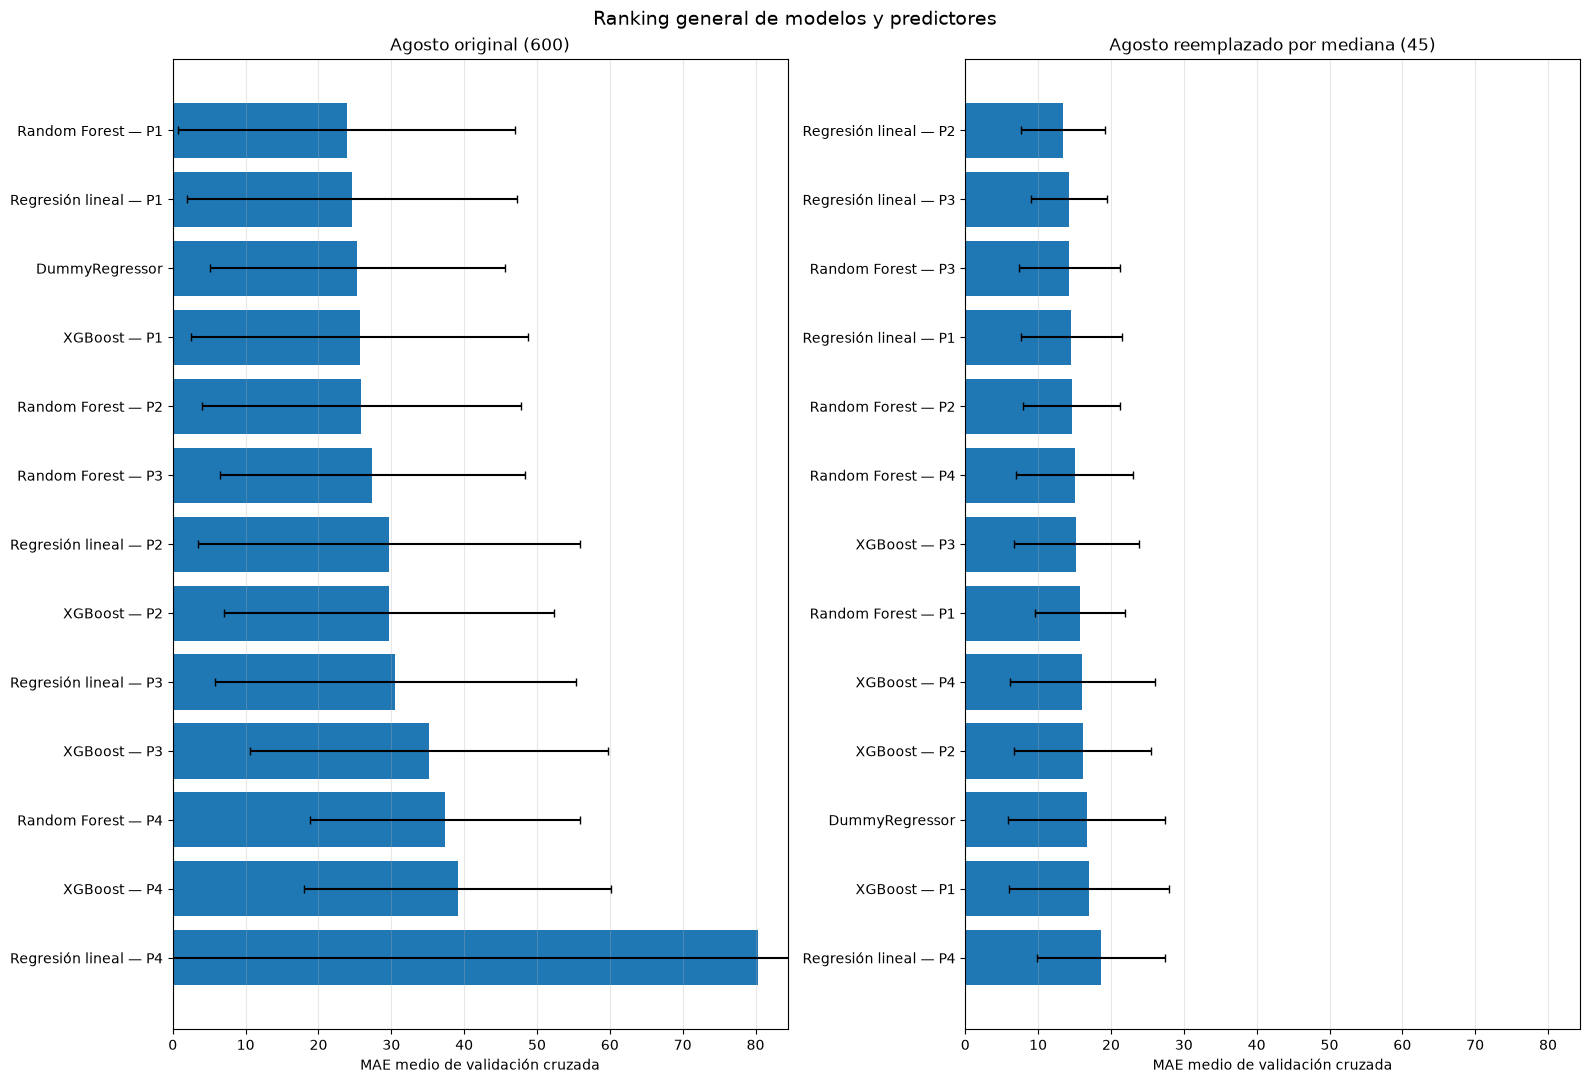

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 11))

escenarios = [
    "Agosto original (600)",
    "Agosto reemplazado por mediana (45)"
]

# Límite común para comparar ambos escenarios
limite_x = (
    tabla_ranking_general_cv["MAE_CV"].max() * 1.05
)

for ax, escenario in zip(ejes, escenarios):

    tabla = tabla_ranking_general_cv.loc[
        tabla_ranking_general_cv["Escenario"] == escenario
    ].sort_values("MAE_CV", ascending=True)

    etiquetas = [
        f"{fila.Modelo} — {fila.Predictor}"
        if fila.Predictor != "—"
        else fila.Modelo
        for fila in tabla.itertuples()
    ]

    ax.barh(
        etiquetas,
        tabla["MAE_CV"],
        xerr=tabla["MAE_CV_std"],
        capsize=3
    )

    ax.set_title(escenario)
    ax.set_xlabel("MAE medio de validación cruzada")
    ax.set_ylabel("")
    ax.set_xlim(0, limite_x)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.3)

fig.suptitle(
    "Ranking general de modelos y predictores",
    fontsize=14
)

plt.tight_layout()
plt.show()

Cómo leerlo:
- Cada barra representa el mejor predictor encontrado para esa familia y ese escenario.
- Una barra más corta indica un MAE medio menor y, por tanto, mejor rendimiento según nuestra métrica principal.
- Las líneas horizontales muestran la desviación estándar del MAE entre los pliegues. Si son grandes, el rendimiento varía bastante según el período evaluado.

## 11.2. Mejores modelos por familia y escenario


In [ ]:

ranking_cv = comparacion_final_cv.copy()

# Identificar predictor
ranking_cv["Predictor"] = (
    ranking_cv["Modelo"]
    .str.extract(r"(Predictor \d+)", expand=False)
    .str.replace("Predictor ", "P", regex=False)
    .fillna("—")
)

# Identificar familia
ranking_cv["Familia"] = "DummyRegressor"

ranking_cv.loc[
    ranking_cv["Modelo"].str.contains(
        "Regresión lineal", case=False
    ),
    "Familia"
] = "Regresión lineal"

ranking_cv.loc[
    ranking_cv["Modelo"].str.contains(
        "Random Forest", case=False
    ),
    "Familia"
] = "Random Forest"

ranking_cv.loc[
    ranking_cv["Modelo"].str.contains(
        "XGBoost", case=False
    ),
    "Familia"
] = "XGBoost"

# Seleccionar el mejor modelo de cada familia y escenario
indices_mejores = (
    ranking_cv
    .sort_values(["MAE_CV", "RMSE_CV"])
    .groupby(["Escenario", "Familia"], sort=False)
    .head(1)
    .index
)

tabla_mejores_modelos_cv = (
    ranking_cv.loc[indices_mejores]
    .copy()
)

# Cambiar las etiquetas para facilitar la lectura
tabla_mejores_modelos_cv["Escenario"] = (
    tabla_mejores_modelos_cv["Escenario"].replace({
        "Agosto original": "Agosto original (600)",
        "Agosto reemplazado por mediana":
            "Agosto reemplazado por mediana (45)"
    })
)

# Ordenar primero por escenario y luego por menor MAE
orden_escenarios = {
    "Agosto original (600)": 1,
    "Agosto reemplazado por mediana (45)": 2
}

tabla_mejores_modelos_cv["orden_escenario"] = (
    tabla_mejores_modelos_cv["Escenario"].map(orden_escenarios)
)

tabla_mejores_modelos_cv = (
    tabla_mejores_modelos_cv
    .sort_values(["orden_escenario", "MAE_CV", "RMSE_CV"])
    .reset_index(drop=True)
)

columnas_resultados = [
    "Escenario", "Familia", "Predictor",
    "MAE_CV", "MAE_CV_std",
    "RMSE_CV", "RMSE_CV_std"
]

display(
    tabla_mejores_modelos_cv[columnas_resultados]
    .round(3)
    .style.hide(axis="index")
)

Escenario,Familia,Predictor,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
Agosto original (600),Random Forest,P1,23.900000,23.141000,47.597000,66.070000
Agosto original (600),Regresión lineal,P1,24.647000,22.630000,48.583000,65.308000
Agosto original (600),DummyRegressor,—,25.352000,20.197000,49.198000,58.093000
Agosto original (600),XGBoost,P1,25.654000,23.099000,50.720000,64.673000
Agosto reemplazado por mediana (45),Regresión lineal,P2,13.412000,5.734000,18.975000,11.186000
Agosto reemplazado por mediana (45),Random Forest,P3,14.264000,6.933000,20.004000,11.977000
Agosto reemplazado por mediana (45),XGBoost,P3,15.259000,8.593000,20.723000,13.214000
Agosto reemplazado por mediana (45),DummyRegressor,—,16.678000,10.789000,21.319000,13.889000


## 11.2.1. Comparación visual de los mejores modelos


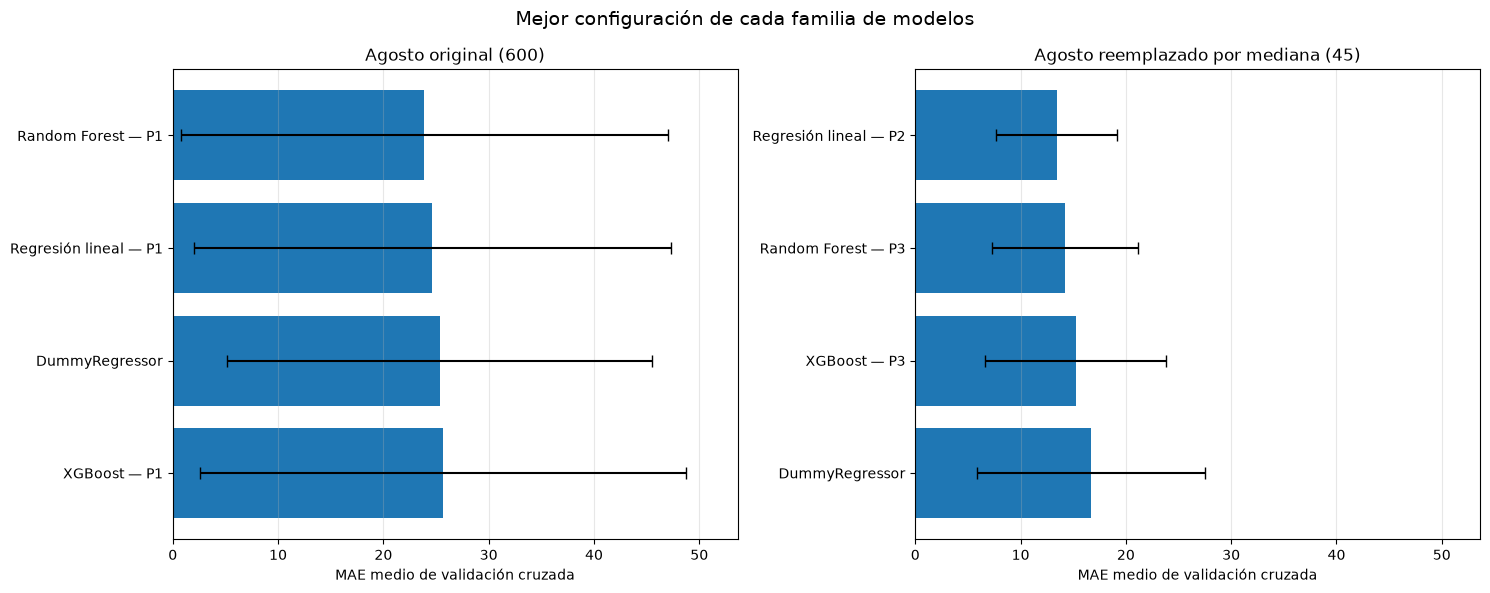

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 6))

escenarios = [
    "Agosto original (600)",
    "Agosto reemplazado por mediana (45)"
]

# Usar el mismo límite del eje X en ambos gráficos
limite_x = (
    tabla_mejores_modelos_cv["MAE_CV"]
    + tabla_mejores_modelos_cv["MAE_CV_std"]
).max() * 1.10

for ax, escenario in zip(ejes, escenarios):

    tabla = tabla_mejores_modelos_cv.loc[
        tabla_mejores_modelos_cv["Escenario"] == escenario
    ].sort_values("MAE_CV", ascending=True)

    etiquetas = [
        f"{fila.Familia} — {fila.Predictor}"
        if fila.Predictor != "—"
        else fila.Familia
        for fila in tabla.itertuples()
    ]

    ax.barh(
        etiquetas,
        tabla["MAE_CV"],
        xerr=tabla["MAE_CV_std"],
        capsize=4
    )

    ax.set_title(escenario)
    ax.set_xlabel("MAE medio de validación cruzada")
    ax.set_ylabel("")
    ax.set_xlim(0, limite_x)
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.3)

fig.suptitle(
    "Mejor configuración de cada familia de modelos",
    fontsize=14
)

plt.tight_layout()
plt.show()

## 11.3. Los cinco mejores modelos del ranking general


In [ ]:
mejores_cinco = (
    tabla_ranking_general_cv
    .sort_values(["MAE_CV", "RMSE_CV"])
    .head(5)
    .reset_index(drop=True)
    .copy()
)

# Recalcular el puesto dentro de los cinco seleccionados
mejores_cinco["Puesto"] = range(1, len(mejores_cinco) + 1)

columnas_mejores = [
    "Puesto", "Modelo", "Predictor", "Escenario",
    "MAE_CV", "MAE_CV_std", "RMSE_CV", "RMSE_CV_std"
]

display(
    mejores_cinco[columnas_mejores]
    .round(3)
    .style.hide(axis="index")
)

Puesto,Modelo,Predictor,Escenario,MAE_CV,MAE_CV_std,RMSE_CV,RMSE_CV_std
1,Regresión lineal,P2,Agosto reemplazado por mediana (45),13.412000,5.734000,18.975000,11.186000
2,Regresión lineal,P3,Agosto reemplazado por mediana (45),14.244000,5.215000,21.087000,12.374000
3,Random Forest,P3,Agosto reemplazado por mediana (45),14.264000,6.933000,20.004000,11.977000
4,Regresión lineal,P1,Agosto reemplazado por mediana (45),14.579000,6.916000,19.856000,12.240000
5,Random Forest,P2,Agosto reemplazado por mediana (45),14.601000,6.704000,20.172000,11.779000


## 11.3.1. Visualización de los cinco mejores modelos


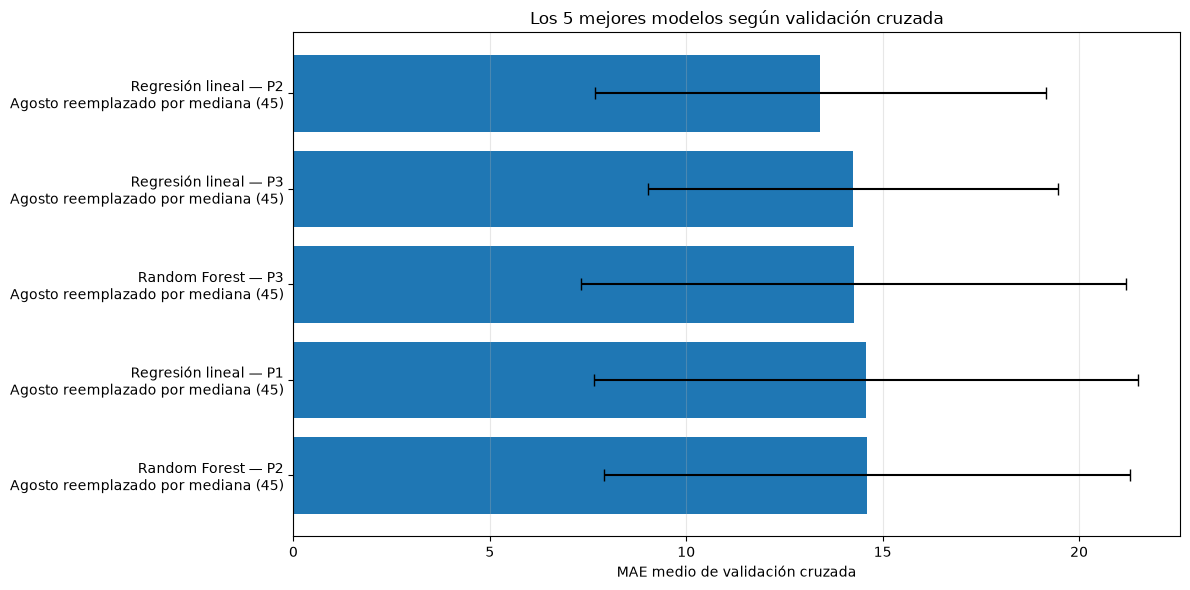

In [38]:
tabla_grafico = mejores_cinco.sort_values(
    "MAE_CV",
    ascending=True
).copy()

etiquetas = []

for fila in tabla_grafico.itertuples():

    if fila.Predictor != "—":
        etiqueta = f"{fila.Modelo} — {fila.Predictor}"
    else:
        etiqueta = fila.Modelo

    etiqueta += f"\n{fila.Escenario}"
    etiquetas.append(etiqueta)

fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(
    etiquetas,
    tabla_grafico["MAE_CV"],
    xerr=tabla_grafico["MAE_CV_std"],
    capsize=4
)

ax.set_title("Los 5 mejores modelos según validación cruzada")
ax.set_xlabel("MAE medio de validación cruzada")
ax.set_ylabel("")
ax.invert_yaxis()
ax.set_xlim(left=0)
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# 12. Comparación de estabilidad: regresión lineal P2 vs. P3


In [39]:

resultados_pliegues = []

# Comparar P2 y P3 en el escenario con agosto reemplazado
predictores_comparar = ["Predictor 2", "Predictor 3"]

for nombre in predictores_comparar:

    datos = datos_modelosA[nombre]

    X_train = datos["X_train"].reset_index(drop=True)
    y_train = datos["y_train"].reset_index(drop=True)

    # Evaluar los mismos cinco pliegues temporales
    for numero_pliegue, (idx_train, idx_val) in enumerate(
        cv_temporal.split(X_train), start=1
    ):

        modelo = Pipeline([
            ("escalador", StandardScaler()),
            ("regresion", LinearRegression())
        ])

        modelo.fit(
            X_train.iloc[idx_train],
            y_train.iloc[idx_train]
        )

        predicciones = modelo.predict(X_train.iloc[idx_val])
        valores_reales = y_train.iloc[idx_val]

        resultados_pliegues.append({
            "Predictor": nombre.replace("Predictor ", "P"),
            "Pliegue": numero_pliegue,
            "MAE": mean_absolute_error(
                valores_reales, predicciones
            ),
            "RMSE": np.sqrt(
                mean_squared_error(valores_reales, predicciones)
            )
        })


# Crear tabla de resultados
tabla_pliegues = pd.DataFrame(resultados_pliegues)

tabla_comparacion_pliegues = tabla_pliegues.pivot(
    index="Pliegue",
    columns="Predictor",
    values=["MAE", "RMSE"]
)

# Simplificar los nombres de las columnas
tabla_comparacion_pliegues.columns = [
    f"{metrica}_{predictor}"
    for metrica, predictor in tabla_comparacion_pliegues.columns
]

tabla_comparacion_pliegues = tabla_comparacion_pliegues.reset_index()

# Diferencia negativa: P2 tiene menor error
tabla_comparacion_pliegues["Diferencia_MAE_P2_menos_P3"] = (
    tabla_comparacion_pliegues["MAE_P2"]
    - tabla_comparacion_pliegues["MAE_P3"]
)

tabla_comparacion_pliegues["Diferencia_RMSE_P2_menos_P3"] = (
    tabla_comparacion_pliegues["RMSE_P2"]
    - tabla_comparacion_pliegues["RMSE_P3"]
)

print("COMPARACIÓN POR PLIEGUE TEMPORAL")
display(tabla_comparacion_pliegues.round(3))

# Resumir cuántos pliegues gana cada predictor
print("\nCANTIDAD DE PLIEGUES CON MENOR ERROR")

print(
    "P2 gana en MAE:",
    (tabla_comparacion_pliegues["Diferencia_MAE_P2_menos_P3"] < 0).sum(),
    "de 5 pliegues"
)

print(
    "P2 gana en RMSE:",
    (tabla_comparacion_pliegues["Diferencia_RMSE_P2_menos_P3"] < 0).sum(),
    "de 5 pliegues"
)


COMPARACIÓN POR PLIEGUE TEMPORAL


,Pliegue,MAE_P2,MAE_P3,RMSE_P2,RMSE_P3,Diferencia_MAE_P2_menos_P3,Diferencia_RMSE_P2_menos_P3
0,1,16.742,16.834,24.600,24.474,-0.092,0.126
1,2,21.134,21.229,35.511,41.165,-0.095,-5.654
2,3,6.073,7.163,7.035,10.260,-1.089,-3.225
3,4,11.388,12.891,13.336,14.123,-1.503,-0.788
4,5,11.723,13.103,14.390,15.414,-1.380,-1.024



CANTIDAD DE PLIEGUES CON MENOR ERROR
P2 gana en MAE: 5 de 5 pliegues
P2 gana en RMSE: 4 de 5 pliegues


# 13. Evaluación final en el conjunto de prueba


In [40]:
# Recuperar los datos de prueba del predictor seleccionado
datos_finales = datos_modelosA["Predictor 2"]

X_train = datos_finales["X_train"]
y_train = datos_finales["y_train"]

X_test = datos_finales["X_test"]
y_test = datos_finales["y_test"]

# Entrenar el modelo con todos los meses de entrenamiento
modelo_final = Pipeline([
    ("escalador", StandardScaler()),
    ("regresion", LinearRegression())
])

modelo_final.fit(X_train, y_train)

# Predecir los 12 meses reservados
predicciones_test = modelo_final.predict(X_test)

# Calcular métricas finales
mae_test = mean_absolute_error(y_test, predicciones_test)

rmse_test = np.sqrt(
    mean_squared_error(y_test, predicciones_test)
)

resultados_test_final = pd.DataFrame({
    "Modelo": ["Regresión lineal"],
    "Predictor": ["P2"],
    "Escenario": ["Agosto reemplazado por mediana"],
    "MAE_test": [mae_test],
    "RMSE_test": [rmse_test]
})

print("RESULTADOS FINALES EN LOS 12 MESES DE PRUEBA")
display(resultados_test_final.round(3))

# Tabla con valores observados y predichos
comparacion_test_final = pd.DataFrame({
    "Año": datos_finales["prueba"]["event_year"].to_numpy(),
    "Mes": datos_finales["prueba"]["event_month"].to_numpy(),
    "Sismos_reales": y_test.to_numpy(),
    "Sismos_predichos": predicciones_test
})

comparacion_test_final["Sismos_predichos"] = (
    comparacion_test_final["Sismos_predichos"].round(2)
)

display(comparacion_test_final)

RESULTADOS FINALES EN LOS 12 MESES DE PRUEBA


,Modelo,Predictor,Escenario,MAE_test,RMSE_test
0,Regresión lineal,P2,Agosto reemplazado por mediana,8.589,10.094


,Año,Mes,Sismos_reales,Sismos_predichos
0,2025,9,49,50.11
1,2025,10,69,48.38
2,2025,11,52,55.95
3,2025,12,54,53.75
4,2026,1,44,54.90
5,2026,2,37,49.15
6,2026,3,36,45.65
7,2026,4,31,42.35
8,2026,5,51,39.55
9,2026,6,39,44.57


## 13.2. Comparación del modelo final con el DummyRegressor


In [41]:
# Recuperar las métricas del Dummy en el mismo escenario
resultado_dummy = test_base.loc[
    (test_base["Escenario"] == "Agosto reemplazado por mediana")
    & (test_base["Predictor"] == "Predictor 2")
].iloc[0]

comparacion_baseline = pd.DataFrame({
    "Modelo": ["DummyRegressor", "Regresión lineal"],
    "Predictor": ["No utiliza predictores", "P2"],
    "MAE_test": [
        resultado_dummy["MAE_test"],
        mae_test
    ],
    "RMSE_test": [
        resultado_dummy["RMSE_test"],
        rmse_test
    ]
})

# Calcular cuánto reduce el error la regresión lineal
reduccion_mae = (
    (resultado_dummy["MAE_test"] - mae_test)
    / resultado_dummy["MAE_test"] * 100
)

reduccion_rmse = (
    (resultado_dummy["RMSE_test"] - rmse_test)
    / resultado_dummy["RMSE_test"] * 100
)

print("COMPARACIÓN SOBRE LOS MISMOS 12 MESES")
display(comparacion_baseline.round(3))

print(f"Reducción del MAE: {reduccion_mae:.1f}%")
print(f"Reducción del RMSE: {reduccion_rmse:.1f}%")

COMPARACIÓN SOBRE LOS MISMOS 12 MESES


,Modelo,Predictor,MAE_test,RMSE_test
0,DummyRegressor,No utiliza predictores,8.356,10.544
1,Regresión lineal,P2,8.589,10.094


Reducción del MAE: -2.8%
Reducción del RMSE: 4.3%


### Conclusión

La regresión lineal con el conjunto de predictores P2 fue seleccionada como la mejor candidata, con un MAE de 13,412 y un RMSE de 18,975 en validación cruzada, mejorando ambas métricas respecto del DummyRegressor. Sin embargo, en el test final de 12 meses, el Dummy obtuvo un MAE ligeramente menor (8,356 frente a 8,589), mientras que la regresión lineal logró un RMSE inferior (10,094 frente a 10,544). Por lo tanto, la regresión mostró un mejor desempeño promedio durante la validación, aunque su ventaja no se mantuvo en todas las métricas del período de prueba.

# 14. Consulta del usuario


## Descripción de la consulta

**Pregunta:** ¿Cuántos sismos se esperan en Argentina durante los próximos X meses?

**Entrada del usuario**
- `meses`: cantidad de meses hacia adelante para los que se solicita la estimación.

**Salida del sistema**
- Cantidad estimada de sismos para el período solicitado.
- Desglose de la estimación por mes.
- Aclaración de que la estimación se basa en el análisis estadístico de la actividad sísmica histórica registrada entre octubre de 2016 y agosto de 2026. No constituye una predicción determinista de eventos individuales.

## 14.1. Preparación del modelo final


In [42]:

columnas_P2 = [
    "sismos_mes_anterior",
    "sismos_ultimos_3_meses",
    "sismos_ultimos_6_meses"
]

# Datos del escenario que reemplaza agosto de 2021 por la mediana
P2_datos_final = predictores_limpiosA["Predictor 2"].copy()

X_final = P2_datos_final[columnas_P2]
y_final = P2_datos_final["cantidad_sismos"]

# Crear y ajustar el modelo operativo
modelo_request = Pipeline([
    ("escalador", StandardScaler()),
    ("regresion", LinearRegression())
])

modelo_request.fit(X_final, y_final)

# Historial de cantidades mensuales conocidas
historial_sismos = y_final.astype(float).tolist()

print("Modelo preparado.")
print("Meses utilizados:", len(P2_datos_final))
print("Últimos registros del historial:")

display(
    P2_datos_final[
        ["event_year", "event_month", "cantidad_sismos"]
        + columnas_P2
    ].tail(6)
)


Modelo preparado.
Meses utilizados: 113
Últimos registros del historial:


,event_year,event_month,cantidad_sismos,sismos_mes_anterior,sismos_ultimos_3_meses,sismos_ultimos_6_meses
107,2026,3,36,37.0,135.0,305.0
108,2026,4,31,36.0,117.0,292.0
109,2026,5,51,31.0,104.0,254.0
110,2026,6,39,51.0,118.0,253.0
111,2026,7,51,39.0,121.0,238.0
112,2026,8,40,51.0,141.0,245.0


## 14.2. Consulta de estimación de actividad sísmica


In [57]:

def consultar_sismos():

    # Solicitar la duración del período de referencia
    while True:
        entrada = input(
            "¿Para cuántos meses querés estimar la cantidad de sismos? (1 a 12): "
        )

        try:
            meses = int(entrada)

            if 1 <= meses <= 12:
                break

            print("Ingresá un número entero entre 1 y 12.")

        except ValueError:
            print("Entrada inválida. Ingresá un número entero.")

    # Copiar el historial sin modificar los datos originales
    historial = historial_sismos.copy()

    total_estimado = 0

    # Estimar la cantidad de sismos para cada mes del período
    for paso in range(meses):

        X_futuro = pd.DataFrame([{
            "sismos_mes_anterior": historial[-1],
            "sismos_ultimos_3_meses": sum(historial[-3:]),
            "sismos_ultimos_6_meses": sum(historial[-6:])
        }])

        prediccion = modelo_request.predict(X_futuro)[0]

        # Evitar cantidades negativas y redondear a enteros
        prediccion = max(0, int(np.floor(prediccion + 0.5)))

        # Acumular la estimación del período
        total_estimado += prediccion

        # Incorporar la estimación al historial para el siguiente paso
        historial.append(prediccion)

    # Mostrar el resultado agregado
    print("\nEstimación de actividad sísmica")
    print(f"Período de referencia: {meses} {'mes' if meses == 1 else 'meses'}")
    print(f"Cantidad total estimada: {total_estimado} sismos")
    print(
        "Estimación basada en los patrones históricos "
        "de actividad sísmica de Argentina."
    )

    return total_estimado


In [61]:

resultado_consulta = consultar_sismos()



Estimación de actividad sísmica
Período de referencia: 6 meses
Cantidad total estimada: 281 sismos
Estimación basada en los patrones históricos de actividad sísmica de Argentina.


## 14.3. Actividad sísmica de los últimos 3 y 6 meses


In [60]:

ultimos_3_meses = historial_sismos[-3:]
ultimos_6_meses = historial_sismos[-6:]

total_3_meses = sum(ultimos_3_meses)
total_6_meses = sum(ultimos_6_meses)

promedio_3_meses = total_3_meses / 3
promedio_6_meses = total_6_meses / 6

print("Actividad sísmica reciente")
print("\nÚltimos 3 meses:")
print(f"Cantidad total de sismos: {total_3_meses:.0f}")
print(f"Promedio mensual: {promedio_3_meses:.2f}")

print("\nÚltimos 6 meses:")
print(f"Cantidad total de sismos: {total_6_meses:.0f}")
print(f"Promedio mensual: {promedio_6_meses:.2f}")


Actividad sísmica reciente

Últimos 3 meses:
Cantidad total de sismos: 130
Promedio mensual: 43.33

Últimos 6 meses:
Cantidad total de sismos: 248
Promedio mensual: 41.33


## 14.4. Diagnóstico de los coeficientes del modelo


In [62]:

coeficientes = pd.DataFrame({
    "Predictor": columnas_P2,
    "Coeficiente": modelo_request.named_steps["regresion"].coef_
})

display(coeficientes)

print(
    "Intercepto:",
    modelo_request.named_steps["regresion"].intercept_
)


,Predictor,Coeficiente
0,sismos_mes_anterior,2.454853
1,sismos_ultimos_3_meses,7.671180
2,sismos_ultimos_6_meses,-0.242542


Intercepto: 49.256637168141594


## 14.5. Comparación entre predicción mensual y recursiva


In [63]:

# 1. Preparar los datos de evaluación
datos = P2_datos_final.reset_index(drop=True).copy()

n_entrenamiento = int(
    modelo_final.named_steps["escalador"].n_samples_seen_
)

n_total = len(datos)
n_test = n_total - n_entrenamiento

print("Meses totales:", n_total)
print("Meses utilizados para entrenar:", n_entrenamiento)
print("Meses reservados para evaluar:", n_test)

# Verificar que el modelo corresponda a la separación esperada
if n_test != 12:
    raise ValueError(
        "El modelo no parece corresponder a una prueba "
        "con los últimos 12 meses. Revisá la separación "
        "de entrenamiento y prueba antes de continuar."
    )

# Separar entrenamiento y prueba
datos_test = datos.iloc[n_entrenamiento:].copy()

# 2. PRUEBA A: predecir usando predictores históricos reales
X_test_real = datos_test[columnas_P2]

predicciones_reales = modelo_final.predict(X_test_real)

# Convertir las predicciones en cantidades enteras no negativas
predicciones_reales = np.maximum(
    0, np.floor(predicciones_reales + 0.5)
).astype(int)

# 3. PRUEBA B: predecir recursivamente
historial = (
    datos.iloc[:n_entrenamiento]["cantidad_sismos"]
    .astype(float)
    .tolist()
)

predicciones_recursivas = []

for paso in range(n_test):

    X_futuro = pd.DataFrame([{
        "sismos_mes_anterior": historial[-1],
        "sismos_ultimos_3_meses": sum(historial[-3:]),
        "sismos_ultimos_6_meses": sum(historial[-6:])
    }])

    prediccion = modelo_final.predict(X_futuro)[0]

    prediccion = max(
        0, int(np.floor(prediccion + 0.5))
    )

    predicciones_recursivas.append(prediccion)
    historial.append(prediccion)

# 4. Comparar ambas pruebas con los valores reales
comparacion = datos_test[
    ["event_year", "event_month", "cantidad_sismos"]
].copy()

comparacion = comparacion.rename(
    columns={"cantidad_sismos": "Sismos reales"}
)

comparacion["Predicción mensual"] = predicciones_reales
comparacion["Predicción recursiva"] = predicciones_recursivas

comparacion["Error mensual"] = (
    comparacion["Predicción mensual"] - comparacion["Sismos reales"]
)

comparacion["Error recursivo"] = (
    comparacion["Predicción recursiva"] - comparacion["Sismos reales"]
)

display(comparacion)

# 5. Resumir los errores y los totales
def calcular_metricas(real, predicho):
    return {
        "MAE": np.mean(np.abs(real - predicho)),
        "RMSE": np.sqrt(np.mean((real - predicho) ** 2)),
        "Total estimado": np.sum(predicho),
        "Error absoluto del total": abs(
            np.sum(predicho) - np.sum(real)
        )
    }

reales = comparacion["Sismos reales"].to_numpy()

metricas = pd.DataFrame({
    "Predicción mensual": calcular_metricas(
        reales, predicciones_reales
    ),
    "Predicción recursiva": calcular_metricas(
        reales, np.array(predicciones_recursivas)
    )
}).T

display(metricas.round(2))

print("\nTotal real del período:", int(np.sum(reales)))


Meses totales: 113
Meses utilizados para entrenar: 101
Meses reservados para evaluar: 12


,event_year,event_month,Sismos reales,Predicción mensual,Predicción recursiva,Error mensual,Error recursivo
101,2025,9,49,50,50,1,1
102,2025,10,69,48,49,-21,-20
103,2025,11,52,56,50,4,-2
104,2025,12,54,54,50,0,-4
105,2026,1,44,55,50,11,6
106,2026,2,37,49,50,12,13
107,2026,3,36,46,50,10,14
108,2026,4,31,42,50,11,19
109,2026,5,51,40,50,-11,-1
110,2026,6,39,45,50,6,11


,MAE,RMSE,Total estimado,Error absoluto del total
Predicción mensual,8.58,10.13,578.0,25.0
Predicción recursiva,8.50,10.82,599.0,46.0



Total real del período: 553
